# 02 - Clasificación

Dos técnicas × 5 configuraciones de hiperparámetros, evaluadas con cross-validation (Tarea 2).

**Decisiones del grupo:**
- **Técnicas:** Árbol de decisión (Clase 3) y Regresión logística (Clase 7). Son modelos muy distintos entre sí (reglas vs. lineal), lo que además favorece al Stacking de la Tarea 3.
- **Cross-validation:** `StratifiedKFold` de 10 folds, con los **mismos folds** para todos los modelos.
- **`Student ID`:** target encoding **dentro de cada fold** (en un `Pipeline`), para evitar *data leakage*.
- **Métricas (Clase 4):** accuracy, precision, recall, F1 y AUC-ROC, con clase positiva 1 = respuesta correcta.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # para poder importar src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
import sklearn
print('scikit-learn', sklearn.__version__)  # se necesita 1.8 o superior (por TargetEncoder y l1_ratio)

from src.utils import TARGET, DATOS_PROCESADOS, RAIZ

RESULTADOS = RAIZ / 'resultados'
SEMILLA = 42

scikit-learn 1.9.1


## 1. Carga de datos

Se usa el dataset generado por el notebook 01 (hay que correrlo antes).

In [2]:
df = pd.read_csv(DATOS_PROCESADOS / 'datos_procesados.csv')

X = df.drop(columns=TARGET)
y = df[TARGET]

print('X:', X.shape, '| y:', y.shape)
print(y.value_counts(normalize=True).round(3))

X: (9546, 239) | y: (9546,)
Type of Answer
0    0.532
1    0.468
Name: proportion, dtype: float64


## 2. Esquema de evaluación

- **Folds:** `StratifiedKFold` con 10 folds y semilla fija. Así todos los modelos (y el Stacking del notebook 03) se evalúan sobre exactamente las mismas particiones.
- **Pipeline:** `TargetEncoder` sobre `Student ID` → modelo. Como el encoder está dentro del pipeline, en cada fold el historial de cada estudiante se calcula **solo con los datos de train**. Los estudiantes que no están en train reciben el promedio general. El resto de las columnas (ya numéricas) pasa sin cambios.
- No se escalan las variables: todas quedan entre 0 y 1 (binarias, o la tasa de acierto del target encoding).
- **No se reporta el accuracy en train.** Dentro del train, `TargetEncoder` calcula el historial con un CV interno (*cross-fitting*) para que el modelo no se entrene con información de la propia respuesta. Al predecir sobre ese mismo train, en cambio, usa el historial completo. Como el modelo ve valores distintos al entrenar y al predecir, el accuracy en train no mide la memorización real y no sirve para detectar overfitting. El overfitting se detecta comparando las métricas de test a medida que aumenta la complejidad del modelo.

In [3]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)

METRICAS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


def crear_pipeline(modelo):
    """Target encoding de Student ID (dentro de cada fold) + modelo."""
    encoder = ColumnTransformer(
        [('te_student', TargetEncoder(target_type='binary'), ['Student ID'])],
        remainder='passthrough',
    )
    return make_pipeline(encoder, modelo)


def evaluar(nombre, modelo, X, y):
    """Evalúa un modelo con cross-validation y devuelve el promedio y el desvío de cada métrica."""
    res = cross_validate(crear_pipeline(modelo), X, y, cv=cv, scoring=METRICAS)
    fila = {'modelo': nombre}
    for m in METRICAS:
        fila[m] = res[f'test_{m}'].mean()
        fila[f'{m}_std'] = res[f'test_{m}'].std()
    return fila


def ic95(valores):
    """Media e intervalo de confianza del 95 % (distribución t de Student)."""
    valores = np.asarray(valores)
    n = len(valores)
    media = valores.mean()
    margen = stats.t.ppf(0.975, n - 1) * valores.std(ddof=1) / np.sqrt(n)
    return media, media - margen, media + margen

## 3. Selección de características: ¿aportan las keywords?

En el EDA vimos que las 191 keywords generan columnas muy dispersas y que la mayoría pertenece a un único subtopic. Antes de entrenar los 10 modelos, se comparan tres conjuntos de columnas usando una configuración intermedia de cada técnica:

| Conjunto | Columnas |
|---|---|
| A. Sin keywords | Student ID, Level, Country, Topic, Subtopic |
| B. Top 30 keywords | A + las 30 keywords más frecuentes |
| C. Todas las keywords | A + las 191 keywords |

In [4]:
cols_kw = [c for c in X.columns if c.startswith('KW_')]
cols_sin_kw = [c for c in X.columns if not c.startswith('KW_')]
top30_kw = X[cols_kw].sum().sort_values(ascending=False).head(30).index.tolist()

conjuntos = {
    'A. Sin keywords': cols_sin_kw,
    'B. Top 30 keywords': cols_sin_kw + top30_kw,
    'C. Todas las keywords': cols_sin_kw + cols_kw,
}

modelos_base = {
    'Árbol (max_depth=8)': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA),
    'Reg. logística (C=1)': LogisticRegression(C=1, max_iter=2000),
}

filas = []
for nombre_conj, cols in conjuntos.items():
    for nombre_mod, modelo in modelos_base.items():
        fila = evaluar(nombre_mod, modelo, X[cols], y)
        fila['conjunto'] = nombre_conj
        fila['n_columnas'] = len(cols)
        filas.append(fila)

sel = pd.DataFrame(filas)
display(sel.pivot_table(index=['conjunto', 'n_columnas'], columns='modelo',
                        values=['accuracy', 'f1', 'roc_auc']).round(3))

accuracy                      \
modelo                           Reg. logística (C=1) Árbol (max_depth=8)   
conjunto              n_columnas                                            
A. Sin keywords       48                        0.652               0.648   
B. Top 30 keywords    78                        0.657               0.651   
C. Todas las keywords 239                       0.659               0.656   

                                                   f1                      \
modelo                           Reg. logística (C=1) Árbol (max_depth=8)   
conjunto              n_columnas                                            
A. Sin keywords       48                        0.624               0.635   
B. Top 30 keywords    78                        0.631               0.632   
C. Todas las keywords 239                       0.632               0.632   

                                              roc_auc                      
modelo                           Reg. logística (C=1) Árbol (max_depth=8)  
conjunto              n_columnas                                           
A. Sin keywords       48                        0.705               0.701  
B. Top 30 keywords    78                        0.705               0.699  
C. Todas las keywords 239                       0.705               0.701

**Conclusión:** 

In [5]:
# Conjunto de columnas elegido para el resto del TP (cambiar si el grupo decide otro)
COLUMNAS = conjuntos['A. Sin keywords']
X_sel = X[COLUMNAS]
print('Columnas usadas:', X_sel.shape[1])

Columnas usadas: 48


## 4. Técnica 1: Árbol de decisión

Se varían la profundidad, el mínimo de muestras por hoja y el criterio de división, de un árbol muy simple (riesgo de *underfitting*) a uno sin límite (riesgo de *overfitting*).

| Config. | Hiperparámetros |
|---|---|
| T1 | `max_depth=3` |
| T2 | `max_depth=5` |
| T3 | `max_depth=8`, `min_samples_leaf=20` |
| T4 | `max_depth=12`, `min_samples_leaf=10`, `criterion='entropy'` |
| T5 | `max_depth=None` (sin límite) |

In [6]:
arboles = {
    'T1 max_depth=3': DecisionTreeClassifier(max_depth=3, random_state=SEMILLA),
    'T2 max_depth=5': DecisionTreeClassifier(max_depth=5, random_state=SEMILLA),
    'T3 max_depth=8, leaf=20': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA),
    'T4 max_depth=12, leaf=10, entropy': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10,
                                                                criterion='entropy', random_state=SEMILLA),
    'T5 sin límite': DecisionTreeClassifier(max_depth=None, random_state=SEMILLA),
}

res_arbol = pd.DataFrame([evaluar(n, m, X_sel, y) for n, m in arboles.items()]).set_index('modelo')
display(res_arbol[METRICAS].round(3))

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
T1 max_depth=3,0.653,0.630,0.637,0.632,0.698
T2 max_depth=5,0.655,0.627,0.652,0.638,0.700
"T3 max_depth=8, leaf=20",0.646,0.618,0.643,0.629,0.695
"T4 max_depth=12, leaf=10, entropy",0.646,0.617,0.642,0.629,0.692
T5 sin límite,0.608,0.585,0.566,0.575,0.620


## 5. Técnica 2: Regresión logística

Se varía la regularización `C` (menor `C` = más regularización = modelo más simple) y el tipo de penalización.

| Config. | Hiperparámetros |
|---|---|
| L1 | `C=0.01` |
| L2 | `C=0.1` |
| L3 | `C=1` (valor por defecto) |
| L4 | `C=10` |
| L5 | `C=1`, penalización L1 (Lasso) |

In [7]:
logisticas = {
    'L1 C=0.01': LogisticRegression(C=0.01, max_iter=2000),
    'L2 C=0.1': LogisticRegression(C=0.1, max_iter=2000),
    'L3 C=1': LogisticRegression(C=1, max_iter=2000),
    'L4 C=10': LogisticRegression(C=10, max_iter=2000),
    'L5 C=1, L1': LogisticRegression(C=1, l1_ratio=1, solver='liblinear', max_iter=2000),
}

res_log = pd.DataFrame([evaluar(n, m, X_sel, y) for n, m in logisticas.items()]).set_index('modelo')
display(res_log[METRICAS].round(3))

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
L1 C=0.01,0.641,0.646,0.519,0.575,0.702
L2 C=0.1,0.652,0.636,0.604,0.619,0.705
L3 C=1,0.652,0.631,0.615,0.623,0.705
L4 C=10,0.651,0.630,0.619,0.624,0.706
"L5 C=1, L1",0.651,0.630,0.619,0.624,0.705


## 6. Promedio de las 5 ejecuciones (Tarea 2.b)

Para cada técnica se promedia cada métrica entre sus 5 configuraciones, con su intervalo de confianza del 95 %.

In [8]:
def resumen_tecnica(res):
    filas = {}
    for m in METRICAS:
        media, inf, sup = ic95(res[m])
        filas[m] = {'media': media, 'IC95 inf': inf, 'IC95 sup': sup}
    return pd.DataFrame(filas).T

promedios = pd.concat({'Árbol de decisión': resumen_tecnica(res_arbol),
                       'Regresión logística': resumen_tecnica(res_log)}, axis=1)
display(promedios.round(3))

Árbol de decisión                   Regresión logística           \
                      media IC95 inf IC95 sup               media IC95 inf   
accuracy              0.642    0.618    0.665               0.649    0.644   
precision             0.615    0.593    0.637               0.634    0.626   
recall                0.628    0.584    0.672               0.595    0.542   
f1                    0.621    0.589    0.653               0.613    0.587   
roc_auc               0.681    0.638    0.724               0.705    0.703   

                    
          IC95 sup  
accuracy     0.655  
precision    0.643  
recall       0.649  
f1           0.639  
roc_auc      0.707

## 7. Comparación de resultados (Tarea 2.c)

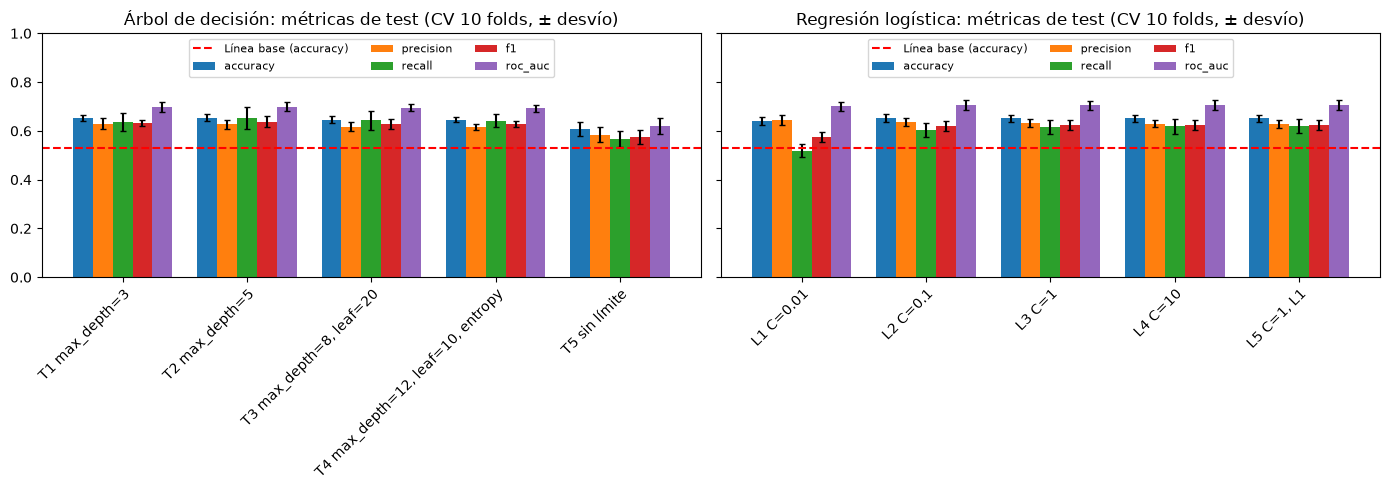

,accuracy,precision,recall,f1,roc_auc
tecnica,,,,,
Reg. logística,0.649,0.634,0.595,0.613,0.705
Árbol,0.642,0.615,0.628,0.621,0.681


In [9]:
# Métricas de cada configuración (promedio de los 10 folds)
comparacion = pd.concat([res_arbol.assign(tecnica='Árbol'), res_log.assign(tecnica='Reg. logística')])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (tecnica, res) in zip(axes, [('Árbol de decisión', res_arbol), ('Regresión logística', res_log)]):
    res[METRICAS].plot.bar(ax=ax, width=0.8, yerr=res[[f'{m}_std' for m in METRICAS]].values.T, capsize=2)
    ax.axhline(y.value_counts(normalize=True).max(), color='red', linestyle='--', label='Línea base (accuracy)')
    ax.set_ylim(0, 1)
    ax.set_title(f'{tecnica}: métricas de test (CV 10 folds, ± desvío)')
    ax.set_xlabel('')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    ax.legend(loc='upper center', ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

display(comparacion.groupby('tecnica')[METRICAS].mean().round(3))

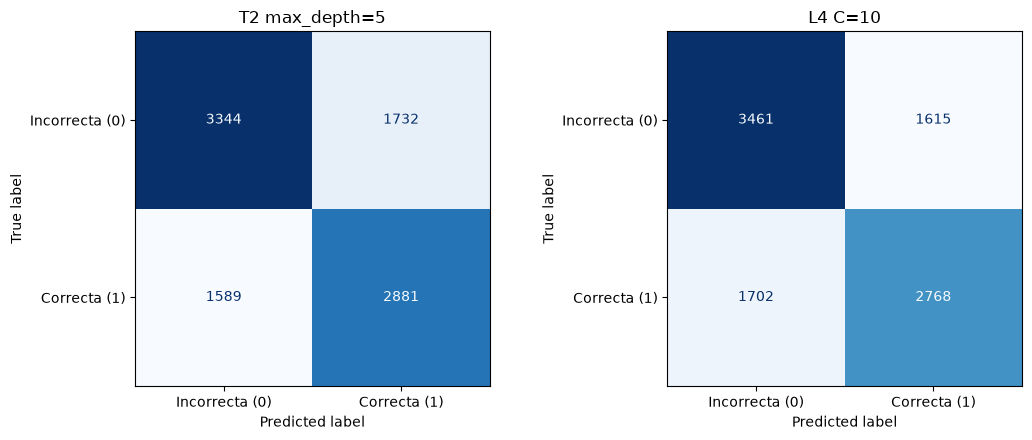

In [10]:
# Matriz de confusión de la mejor configuración de cada técnica (según AUC)
mejor_arbol = res_arbol['roc_auc'].idxmax()
mejor_log = res_log['roc_auc'].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nombre, modelo) in zip(axes, [(mejor_arbol, arboles[mejor_arbol]),
                                       (mejor_log, logisticas[mejor_log])]):
    y_pred = cross_val_predict(crear_pipeline(modelo), X_sel, y, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=['Incorrecta (0)', 'Correcta (1)'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

In [11]:
# Se guardan los resultados para el notebook 03 y el informe
comparacion.to_csv(RESULTADOS / 'resultados_tarea2.csv')
promedios.to_csv(RESULTADOS / 'promedios_tarea2.csv')
sel.to_csv(RESULTADOS / 'seleccion_caracteristicas.csv', index=False)
print('Guardado en', RESULTADOS.relative_to(RAIZ))

Guardado en resultados


## 8. Conclusiones

